# Сессионный проект. Внедрение алгоритма выбора слота доставки

Сосновский Егор, М26-515

**Решение: модифицировать алгоритм и повторить пилот.** рост конверсии сопровождается ухудшением защитной метрики. оценка относится к синтетическому сценарию, а не к действующему сервису.

моделируется запуск алгоритма в 20 из 40 городов с 17 августа 2026 года. более крупные города получают его первыми из-за готовности инфраструктуры. рандомизации нет. наблюдаются 6 недель до запуска и 6 после, по 27 сентября. алгоритм меняет доступные слоты, поэтому варианты внутри одного города мешали бы друг другу.

данные сгенерированы один раз с seed `20261103`. в модели есть различия городов, общий тренд, недельная сезонность и зависимость соседних дней. исходный `delivery_slots_city_day.csv` загружается отдельно в рабочую папку Colab. ноутбук его только читает.

## 1. Данные и разведочный анализ

### Условие

Проверить качество данных, состав групп, баланс до внедрения и сезонность.

### Решение

одна строка соответствует городу и дню. `treated` отмечает города внедрения, `users` считает пользователей, открывших выбор слота, `converted` пользователей с оформленным заказом, `errors` пользователей хотя бы с одной ошибкой оформления. конверсия и ошибка могут встретиться у одного пользователя в один день. показатели делятся на `users`.

баланс оценивается по средним каждого города до запуска. SMD равен разнице средних, делённой на общий масштаб разброса. города имеют равный вес. SRM относительно 50/50 пользователей здесь неприменим: случайного назначения не было. вместо этого проверяются 20 городов в каждой группе и полнота панели.

### Код

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests
from scipy.stats import t
from IPython.display import display

ALPHA, ERROR_LIMIT = 0.05, 0.002  # допустимый рост ошибок: 0,2 п.п.
try:
    df = pd.read_csv('delivery_slots_city_day.csv', parse_dates=['date'])
except FileNotFoundError:
    raise FileNotFoundError('Загрузите delivery_slots_city_day.csv в рабочую папку ноутбука.') from None
assert set(df.columns) == {'city', 'date', 'treated', 'users', 'converted', 'errors'}
assert not df.isna().any().any() and not df.duplicated(['city', 'date']).any()
assert df.treated.isin([0, 1]).all() and (df.users > 0).all()
for column in ['users', 'converted', 'errors']:
    assert np.isfinite(df[column]).all() and (df[column] % 1 == 0).all()
for column in ['converted', 'errors']:
    assert df[column].between(0, df.users).all()
assert df.groupby('city').treated.nunique().eq(1).all()
assert df.groupby('city').size().eq(84).all() and df.city.nunique() == 40
assert df.date.nunique() == 84 and df.date.min() == pd.Timestamp('2026-07-06')
assert df.date.max() == pd.Timestamp('2026-09-27')
assert df[['city', 'treated']].drop_duplicates().groupby('treated').size().eq(20).all()
df['day'] = (df.date - df.date.min()).dt.days
df['post'] = (df.day >= 42).astype(int)
df['did'] = df.treated * df.post
df['week'] = df.day // 7 - 6
df['trend'] = df.treated * (df.day - 42)
df['conversion'] = df.converted / df.users
df['error_rate'] = df.errors / df.users
pre = df.loc[df.post == 0].groupby(['city', 'treated'])[['users', 'conversion', 'error_rate']].mean().reset_index()
balance = []
for metric in ['users', 'conversion', 'error_rate']:
    a, b = [pre.loc[pre.treated == group, metric] for group in [0, 1]]
    balance.append([metric, a.mean(), b.mean(), (b.mean() - a.mean()) / np.sqrt((a.var() + b.var()) / 2)])
balance = pd.DataFrame(balance, columns=['Метрика до запуска', 'Контроль', 'Внедрение', 'SMD'])
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 10, 'figure.dpi': 110})
pd.set_option('display.max_colwidth', None)

### Проверка

3360 строк, 40 городов, 84 дней


,Метрика до запуска,Контроль,Внедрение,SMD
0,users,658.4643,1086.2488,3.8184
1,conversion,0.0893,0.1009,1.2395
2,error_rate,0.0153,0.0156,0.1725


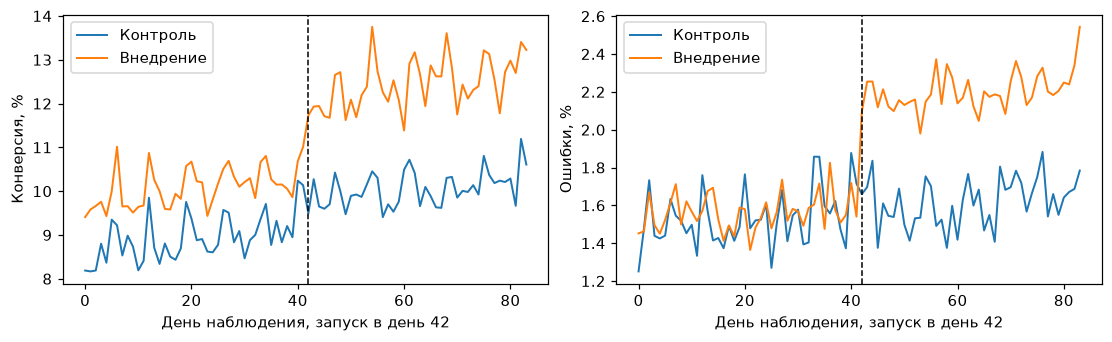

In [2]:
print(f'{len(df)} строк, {df.city.nunique()} городов, {df.date.nunique()} дней')
display(balance.round(4))
fig, axes = plt.subplots(1, 2, figsize=(10, 3), layout='constrained')
for metric, ax, title in zip(['conversion', 'error_rate'], axes, ['Конверсия, %', 'Ошибки, %']):
    for group, label in [(0, 'Контроль'), (1, 'Внедрение')]:
        series = df.loc[df.treated == group].groupby('day')[metric].mean()
        ax.plot(series.index, 100 * series, label=label, linewidth=1.3)
    ax.axvline(42, color='black', linestyle='--', linewidth=1)
    ax.set(xlabel='День наблюдения, запуск в день 42', ylabel=title)
    ax.legend()
plt.show()

города различаются по исходному потоку и конверсии. это ожидаемо при отборе крупных городов. на графике видны колебания с периодом в неделю. простая разница между группами смешает исходные различия с эффектом внедрения.

## 2. Метод и проверка предпосылок

### Условие

Обосновать причинный метод и проверить его допущения.

### Решение

выбран DiD, разность изменений конверсии в двух группах. модель `y = эффект города + эффект даты + tau × treated × post + ошибка`. эффекты города учитывают постоянные различия, эффекты каждой даты убирают общую сезонность, тренд и общий шок после запуска. `tau` оценивает среднее изменение для города внедрения, каждый город имеет равный вес.

нужны параллельные изменения без внедрения, отсутствие предварительной реакции и влияния между городами, неизменная регистрация событий и отсутствие иных изменений только в группе внедрения. в генераторе эти условия заложены. в реальном сервисе потребовались бы журнал релизов и проверка перетока пользователей. значимый дисбаланс уровней сам по себе не опровергает DiD.

RDD потребовал бы точного показателя назначения и достаточного числа городов около порога. в CSV есть только наблюдаемый поток, 40 городов мало для локальной оценки. для IV нет инструмента, для PSM почти нет перекрытия по размеру городов. возможный будущий дизайн: кластерный A/B по городам с рандомизацией внутри групп размера. в текущем сценарии сроки заданы готовностью инфраструктуры.

ошибки модели кластеризуются по 40 городам, чтобы учитывать зависимость дней. используется поправка на число кластеров и t-распределение с 39 степенями свободы. недельные взаимодействия сравниваются с последней неделей до запуска. совместный F-тест пяти предшествующих коэффициентов проверяется для обеих метрик. отсутствие значимости не доказывает параллельность будущих трендов.

### Код

In [3]:
def fit_model(data, metric, extra='did', weights=None):
    # C() задаёт отдельный эффект для каждого города и каждой даты
    formula = f'{metric} ~ C(city) + C(day) + {extra}'
    model = smf.ols(formula, data=data) if weights is None else smf.wls(formula, data=data, weights=weights)
    return model.fit(cov_type='cluster', cov_kwds={'groups': data.city,
                     'use_correction': True, 'df_correction': True}, use_t=True)

def effect_row(model, label):
    low, high = model.conf_int(alpha=ALPHA).loc['did']
    return {'Модель': label, 'Эффект, п.п.': 100 * model.params['did'],
            'Нижняя граница': 100 * low, 'Верхняя граница': 100 * high,
            'p-value': model.pvalues['did']}

weeks = [week for week in range(-6, 6) if week != -1]
terms = [f'event_{week + 6}' for week in weeks]
for week, name in zip(weeks, terms):
    df[name] = df.treated * (df.week == week)
event_models = {metric: fit_model(df, metric, ' + '.join(terms)) for metric in ['conversion', 'error_rate']}
pre_terms = [name for week, name in zip(weeks, terms) if week < -1]
pre_tests = []
for metric, model in event_models.items():
    test = model.f_test(', '.join(name + ' = 0' for name in pre_terms))
    pre_tests.append([metric, float(test.fvalue), float(test.pvalue)])

### Проверка

,Метрика,F предтрендов,p-value
0,conversion,0.7038,0.6240
1,error_rate,0.3004,0.9096


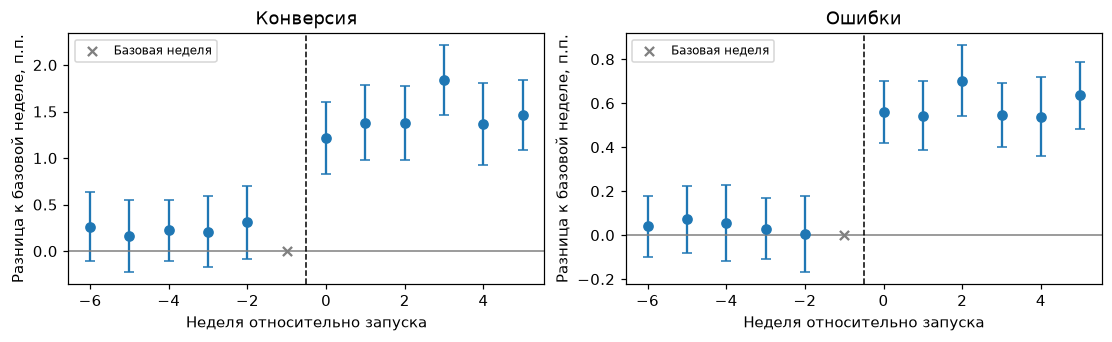

In [4]:
display(pd.DataFrame(pre_tests, columns=['Метрика', 'F предтрендов', 'p-value']).round(4))
fig, axes = plt.subplots(1, 2, figsize=(10, 3), layout='constrained')
for metric, title, ax in zip(['conversion', 'error_rate'], ['Конверсия', 'Ошибки'], axes):
    model = event_models[metric]
    estimate = 100 * model.params[terms].to_numpy()
    interval = 100 * model.conf_int().loc[terms].to_numpy()
    ax.errorbar(weeks, estimate, yerr=[estimate - interval[:, 0], interval[:, 1] - estimate], fmt='o', capsize=3)
    ax.scatter([-1], [0], color='gray', marker='x', label='Базовая неделя')
    ax.axhline(0, color='gray', linewidth=1)
    ax.axvline(-0.5, color='black', linestyle='--', linewidth=1)
    ax.set(xlabel='Неделя относительно запуска', ylabel='Разница к базовой неделе, п.п.', title=title)
    ax.legend(fontsize=8)
plt.show()

совместные тесты предтрендов дали p = 0,624 для конверсии и 0,910 для ошибок. отклонения до запуска не обнаружены. интервалы на графике точечные, 95%, а не одновременные. эта диагностика не исключает необнаруженный тренд или совпавший по времени отдельный шок группы внедрения.

## 3. Эффект и устойчивость

### Условие

Оценить эффект с доверительным интервалом и проверить чувствительность к спецификации.

### Решение

основная оценка использует все 84 дня. дополнительно сравниваются окно 28 дней до и после, отдельный линейный тренд группы внедрения и фиксированные веса по среднему числу пользователей до запуска. последний вариант оценивает эффект с большим весом крупных городов, поэтому его целевой показатель отличается. постфактум выбирать самую выгодную модель нельзя. проверки устойчивости являются диагностическими.

### Код

In [5]:
main = fit_model(df, 'conversion')
guard = fit_model(df, 'error_rate')
fixed_weights = df.city.map(pre.set_index('city').users)
models = {
    'Основная, 42 дня до и после': main,
    'Окно 28 дней до и после': fit_model(df.loc[df.day.between(14, 69)], 'conversion'),
    'Линейный тренд группы': fit_model(df, 'conversion', 'did + trend'),
    'Веса по users до запуска': fit_model(df, 'conversion', weights=fixed_weights),
}
effects = pd.DataFrame([effect_row(model, label) for label, model in models.items()])
# Семейство двух тестов нулевого эффекта: конверсия и ошибки
holm = multipletests([main.pvalues['did'], guard.pvalues['did']], alpha=ALPHA, method='holm')[1]

### Проверка

,Модель,"Эффект, п.п.",Нижняя граница,Верхняя граница,p-value
0,"Основная, 42 дня до и после",1.246,1.062,1.429,1.7e-16
1,Окно 28 дней до и после,1.268,1.071,1.464,8.35e-16
2,Линейный тренд группы,1.160,0.879,1.441,3.26e-10
3,Веса по users до запуска,1.259,1.089,1.428,8.21e-18


p-value конверсии после Холма: 1.7e-16


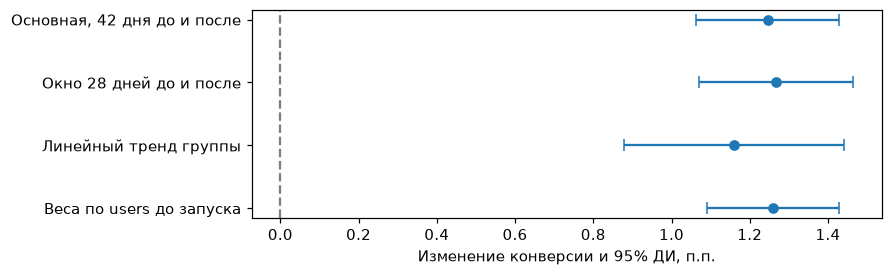

In [6]:
effect_view = effects.round(3)
effect_view['p-value'] = effects['p-value'].map('{:.3g}'.format)
display(effect_view)
print(f'p-value конверсии после Холма: {holm[0]:.3g}')
fig, ax = plt.subplots(figsize=(8, 2.4), layout='constrained')
estimate = effects['Эффект, п.п.'].to_numpy()
ax.errorbar(estimate, np.arange(len(effects)),
            xerr=[estimate - effects['Нижняя граница'], effects['Верхняя граница'] - estimate], fmt='o', capsize=4)
ax.set_yticks(np.arange(len(effects)), effects['Модель'])
ax.axvline(0, color='gray', linestyle='--')
ax.set_xlabel('Изменение конверсии и 95% ДИ, п.п.')
ax.invert_yaxis()
plt.show()

во всех четырёх спецификациях 95% интервал изменения конверсии выше нуля. оценки от +1,160 до +1,268 п.п. устойчивы к выбранным изменениям модели, но не проверяют отсутствие всех возможных смешивающих факторов.

## 4. Защитная метрика

### Условие

Проверить ухудшение частоты ошибок и учесть его при решении.

### Решение

ошибки оцениваются тем же DiD с эффектами города и даты. до расчёта задан предел допустимого роста +0,2 п.п. отдельный односторонний тест проверяет превышение этого предела. для допуска к запуску верхняя односторонняя 95% граница должна быть ниже +0,2 п.п. простого p > 0,05 в тесте нулевого изменения для вывода о безопасности недостаточно.

### Код

In [7]:
guard_effect = float(guard.params['did'])
guard_se = float(guard.bse['did'])
cluster_df = df.city.nunique() - 1
p_harm = float(t.sf((guard_effect - ERROR_LIMIT) / guard_se, cluster_df))
upper_safe = guard_effect + t.ppf(1 - ALPHA, cluster_df) * guard_se
guard_table = pd.DataFrame([effect_row(guard, 'Ошибки оформления')])
guard_table['p после Холма'] = holm[1]

### Проверка

In [8]:
guard_view = guard_table.round(3)
for column in ['p-value', 'p после Холма']:
    guard_view[column] = guard_table[column].map('{:.3g}'.format)
display(guard_view)
print(f'p превышения +0,2 п.п.: {p_harm:.3g}')
print(f'Верхняя односторонняя 95% граница: {100 * upper_safe:.3f} п.п.')
print('Защитная метрика допускает запуск' if upper_safe < ERROR_LIMIT else 'Условие безопасности не выполнено')

,Модель,"Эффект, п.п.",Нижняя граница,Верхняя граница,p-value,p после Холма
0,Ошибки оформления,0.554,0.494,0.613,4.11e-21,8.21e-21


p превышения +0,2 п.п.: 6.12e-15
Верхняя односторонняя 95% граница: 0.603 п.п.
Условие безопасности не выполнено


## 5. Продуктовое решение

### Условие

Выбрать внедрение, откат или модификацию с учётом метрик и бизнес-контекста.

### Решение

для расчёта масштаба приняты учебные допущения: 300 руб. вклада с дополнительного заказа и 5000 руб. расходов на город в месяц. используются исходный поток городов внедрения и 30 дней. это сценарий, расходы из-за ошибок в него не включены. положительная сумма не отменяет защитную метрику. результат средний для изученных городов, перенос на все города или отдельные сегменты не доказан.

### Код

In [9]:
users_month = 30 * pre.loc[pre.treated == 1, 'users'].mean()
additional_orders = users_month * main.params['did']
contribution = 300 * additional_orders - 5000
primary_positive = main.conf_int().loc['did', 0] > 0 and holm[0] < ALPHA
safe = upper_safe < ERROR_LIMIT
if primary_positive and safe:
    decision = 'Ограниченное расширение с контролем метрик'
elif guard_effect > ERROR_LIMIT and p_harm < ALPHA:
    decision = 'Модифицировать алгоритм и повторить пилот'
else:
    decision = 'Не расширять, продолжить проверку'

### Проверка

In [10]:
print(f'Дополнительные заказы на город в месяц: {additional_orders:.1f}')
print(f'Вклад за вычетом внедрения, без издержек ошибок: {contribution:,.0f} руб.')
print(decision)

Дополнительные заказы на город в месяц: 405.9
Вклад за вычетом внедрения, без издержек ошибок: 116,764 руб.
Модифицировать алгоритм и повторить пилот


при росте конверсии на 1,246 п.п. (95% ДИ от 1,062 до 1,429) ошибки увеличились на 0,554 п.п. (95% ДИ от 0,494 до 0,613). весь интервал ошибок выше допустимых +0,2 п.п. текущий алгоритм не переносить на все города, в пилоте вернуть прежний выбор слотов. исправить причину ошибок и провести новый кластерный A/B в городах с готовой инфраструктурой. до его начала зафиксировать метрики, допустимый рост ошибок, объём и срок. промежуточное подглядывание и остановка по удобному p-value в текущей симуляции не применялись.

## 6. Наивная оценка и контроль сезонности

### Условие

Сравнить DiD с простыми средними и пояснить контроль потенциальных смешивающих факторов.

### Решение

сравниваются изменения средних долей с одинаковым весом городов. простое до/после включает общий рост спроса, а сравнение групп после запуска включает исходное преимущество крупных городов. DiD вычитает изменение контроля. эффекты дат контролируют общий недельный рисунок и общие шоки. они не убирают изменения только в группе внедрения, для этого нужны дополнительные данные или новый эксперимент.

### Код

In [11]:
means = df.groupby(['treated', 'post']).conversion.mean().unstack('post')
before_after = means.loc[1, 1] - means.loc[1, 0]
after_groups = means.loc[1, 1] - means.loc[0, 1]
manual_did = before_after - (means.loc[0, 1] - means.loc[0, 0])
assert np.isclose(manual_did, main.params['did'])
naive = pd.DataFrame({'Оценка': ['До/после в городах внедрения', 'Между группами после', 'DiD'],
                      'Разница, п.п.': 100 * np.array([before_after, after_groups, manual_did])})

### Проверка

In [12]:
display(naive.round(3))

,Оценка,"Разница, п.п."
0,До/после в городах внедрения,2.364
1,Между группами после,2.401
2,DiD,1.246
